## Classical Image Segmentation Pipeline: Mango Leaf Disease & Spot Extraction

### <b> 1. BUSINESS UNDERSTANDING </b>

<p style='text-align:justify; background-color: #cbe4f2;  color: black ; padding: 20px;   border-radius: 12px;font-family: Arial, sans-serif; font-size: 16px; display: inline-block;'> Anthracnose, caused by Colletotrichum gloeosporioides, is a major disease of mango that reduces leaf health and crop yield. Severity is still commonly assessed by manual visual inspection, which is subjective, time-consuming, and impractical for large orchards. This study applies classical thresholding to segment anthracnose lesions from healthy leaf tissue, as a simple, fast, and low-cost approach that requires no labeled training data. Two color spaces, HSV and CIELAB, are compared to determine which separates lesions more effectively. The segmentation results are expected to support objective estimation of the infected area for early disease detection and management.</p>

### <b>  2. DATA UNDERSTANDING </b>

Shape H x W x C : (240, 240, 3)
Data type       : uint8
Pixel range     : [0, 240]


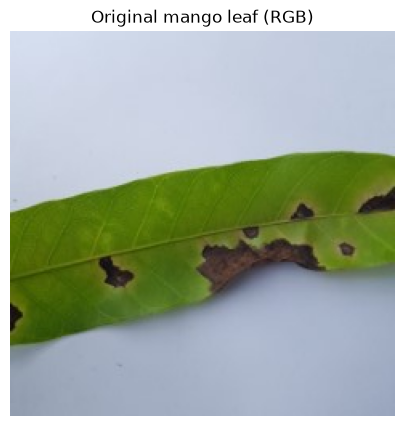

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

rgb = cv2.imread('sample_img.jpg') #Input your sample_img.jpg
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB) 

print(f"Shape H x W x C : {rgb.shape}")
print(f"Data type       : {rgb.dtype}")
print(f"Pixel range     : [{rgb.min()}, {rgb.max()}]")

plt.figure(figsize=(5, 5))
plt.imshow(rgb)
plt.title("Original mango leaf (RGB)")
plt.axis("off")
plt.show()

#### <b> 2.1 Color space primer </b>

| Space | Channels | What it separates | Storage in OpenCV (8-bit) |
|---|---|---|---|
| **RGB** | R, G, B | Nothing: brightness and color are mixed, so *all three* channels change with illumination. | 0 to 255 |
| **HSV** | **H**ue (angle), **S**aturation, **V**alue (= max(R, G, B)) | Chromatic information (H, S) from brightness (V). Easy to interpret, but cylindrical and not perceptually uniform. | H: 0 to 179 (degrees / 2), S and V: 0 to 255 |
| **CIELAB** | **L\*** lightness, **a\*** green to red, **b\*** blue to yellow | Lightness (L\*) from chromaticity (a\*, b\*). Designed so that Euclidean distance approximates perceived color difference (ΔE). | L = L\* × 255/100, a = a\* + 128, b = b\* + 128 |

**Pitfalls to keep in mind**
- **Hue is circular** (red sits at both 0 and 179). Averaging or Otsu-thresholding hue is only meaningful when the region of interest does not wrap around the red boundary.
- **Hue is unstable when saturation is low** (gray, white, or very dark pixels have an arbitrary hue).
- **OpenCV's 8-bit Lab is offset and rescaled.** Neutral gray is a = b = 128, not 0. Convert from float32 in [0, 1] to obtain true L\*a\*b\* values.
- **V is not lightness.** V = max(R, G, B), so a saturated pure blue and a white pixel have the same V; L\* distinguishes them.

In [2]:
# 8-bit Lab (OpenCV storage) vs true Lab (float input) for one pixel
y, x = rgb.shape[0] // 2, rgb.shape[1] // 2
lab8     = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
lab_true = cv2.cvtColor(rgb.astype(np.float32) / 255.0, cv2.COLOR_RGB2LAB)

print("Pixel (row, col):", (y, x))
print("8-bit  (L, a, b)      :", lab8[y, x])
print("True   (L*, a*, b*)   :", lab_true[y, x].round(1))
print("From 8-bit, rescaled  :", (round(int(lab8[y, x, 0]) * 100 / 255, 1),
                                  int(lab8[y, x, 1]) - 128,
                                  int(lab8[y, x, 2]) - 128))

Pixel (row, col): (120, 120)
8-bit  (L, a, b)      : [113 104 174]
True   (L*, a*, b*)   : [ 44.1 -24.3  46.2]
From 8-bit, rescaled  : (44.3, -24, 46)


<div style='text-align:justify; background-color: #cbe4f2;  color: black ; padding: 20px;   border-radius: 12px;font-family: Arial, sans-serif; font-size: 16px; display: inline-block;'>
This Code show :

- <b> Pixel (row, col): (120, 120) </b>

    - The code is looking at one specific pixel located at row 120 and column 120 in the image.
- <b> 8-bit (L, a, b) : [113 104 174] </b>
    - This is how OpenCV stores the color values using standard 8-bit numbers (from 0 to 255).
- <b> True (L*, a*, b*) : [44.1 -24.3 46.2] </b>
    - This is the real, standard scientific Lab color value (using decimals). Here, lightness ($L^*$) is 44.1 (out of 100), and $a^*$ / $b^*$ show the true color balance without any OpenCV shifting.
- <b> From 8-bit, rescaled : (44.3, -24, 46) </b>
    - This line takes the 8-bit numbers (113, 104, 174), applies the reverse math formulas (like subtracting 128 from $a$ and $b$), and converts them back. As you can see, the result is almost identical to the True Lab values

#### <b> 2.2 HSV exploration </b>

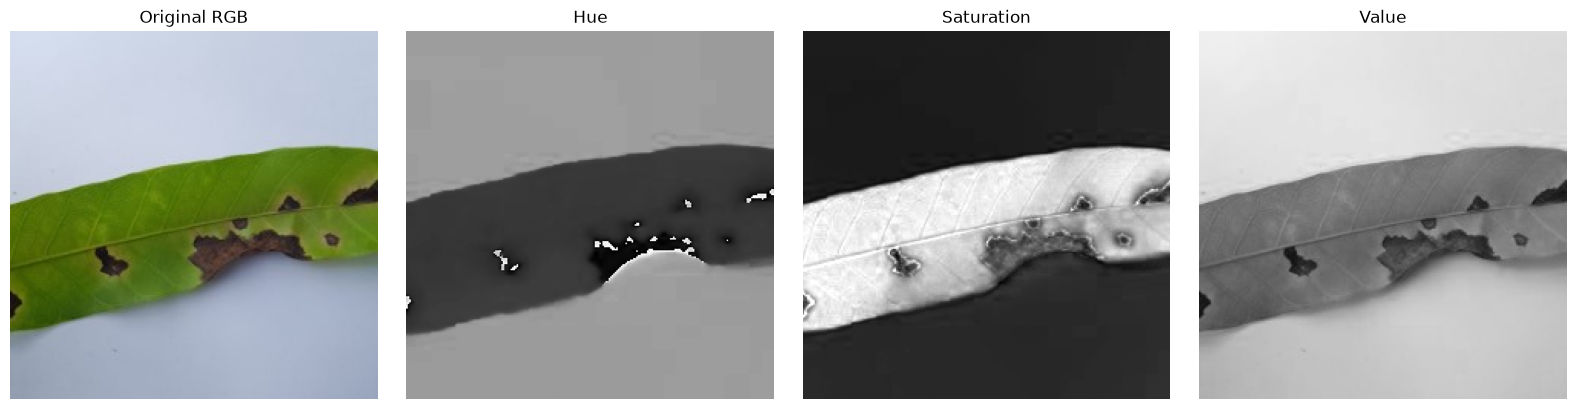

In [3]:
hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
H, S, V = cv2.split(hsv)


# Split the three HSV channels
hue = hsv[:, :, 0]
saturation = hsv[:, :, 1]
value = hsv[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(rgb)
axes[0].set_title("Original RGB")

axes[1].imshow(hue, cmap="gray", vmin=0, vmax=179)
axes[1].set_title("Hue")

axes[2].imshow(saturation, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Saturation")

axes[3].imshow(value, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Value")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

**How to read each channel (grayscale display)**

| Channel | Dark pixel | Bright pixel | Note |
|---|---|---|---|
| **H** (0-179) | Hue near red (0) | Hue near magenta (179) | Yellow ≈ 30, green ≈ 60, blue ≈ 120. Circular: dark and bright are *neighbors* on the color wheel. |
| **S** (0-255) | Washed-out, gray, or white | Pure, vivid color | Healthy green leaf is highly saturated; white or gray background is not. |
| **V** (0-255) | Little light returned (shadow, necrosis) | Maximum brightness | Similar to L\* but computed as max(R, G, B). |

### <b> why dark or low-intensity areas become mathematically unstable in the Hue channel? </b>

<p style='text-align:justify; background-color: #cbe4f2;  color: black ; padding: 20px;   border-radius: 12px;font-family: Arial, sans-serif; font-size: 16px; display: inline-block;'>
Dark or low-intensity areas become unstable in the Hue channel because the formula calculates color angles by comparing the proportions of Red, Green, and Blue values. When pixels are very dark, all three channels drop close to zero and become nearly identical, causing tiny digital noise to be massively magnified into random, erratic values that show up as bright white spots
</p>

#### <b> Histogram of HSV Component </b>



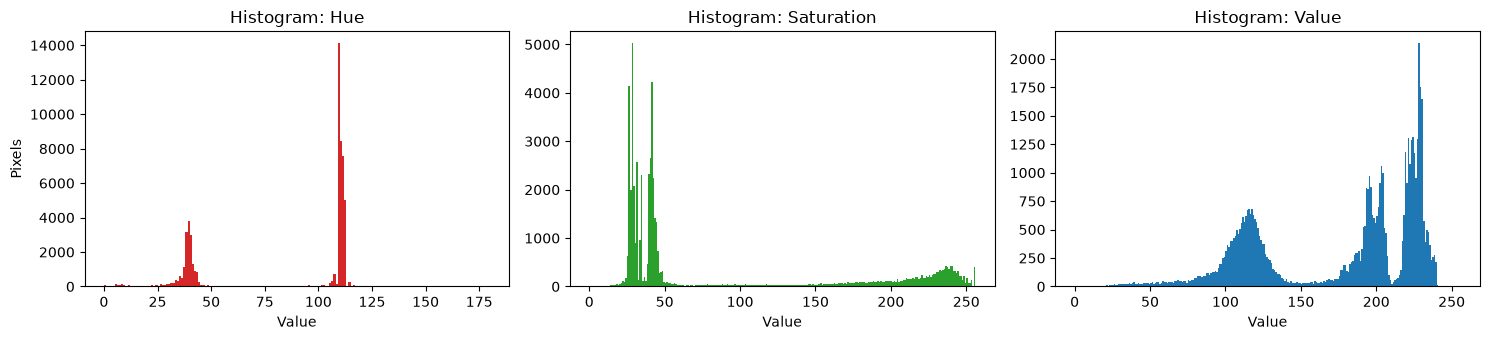

In [4]:
# Histograms of the three HSV channels (whole image)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, ch, name, rng, col in zip(axes, [H, S, V], ["Hue", "Saturation", "Value"],
                                  [(0, 180), (0, 256), (0, 256)], ["tab:red", "tab:green", "tab:blue"]):
    ax.hist(ch.ravel(), bins=rng[1] - rng[0], range=rng, color=col)
    ax.set_title(f"Histogram: {name}")
    ax.set_xlabel("Value")
axes[0].set_ylabel("Pixels")
plt.tight_layout()
plt.show()

### <b> HISTOGRAM FOR LEAF (green : 25 - 60) (Initial Prediction)

Pixels inside hue band [25, 60]: 30.9% of the image


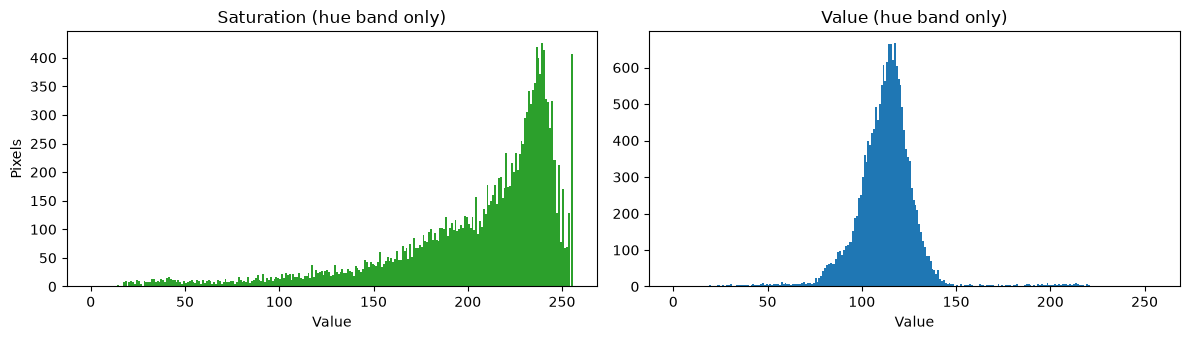

In [5]:
# Where do yellow/brown pixels live in S and V?
# Restrict to a hue band (OpenCV hue 5-25 = orange-brown/yellow) and inspect S and V there.
HUE_LO, HUE_HI = 25, 60
hue_band = (H >= HUE_LO) & (H <= HUE_HI)
print(f"Pixels inside hue band [{HUE_LO}, {HUE_HI}]: {hue_band.mean() * 100:.1f}% of the image")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(S[hue_band], bins=256, range=(0, 256), color="tab:green")
axes[0].set_title("Saturation (hue band only)")
axes[1].hist(V[hue_band], bins=256, range=(0, 256), color="tab:blue")
axes[1].set_title("Value (hue band only)")
for ax in axes:
    ax.set_xlabel("Value")
axes[0].set_ylabel("Pixels")
plt.tight_layout()
plt.show()

### <b> HISTOGRAM FOR Background (blue : 100 - 120) (Initial Prediction)

Pixels inside hue band [100, 120]: 64.8% of the image


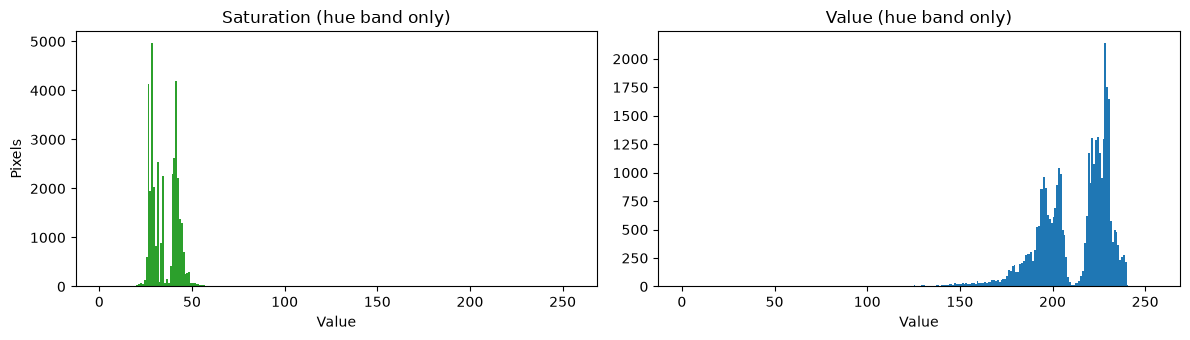

In [6]:
# Where do yellow/brown pixels live in S and V?
# Restrict to a hue band (OpenCV hue 5-25 = orange-brown/yellow) and inspect S and V there.
HUE_LO, HUE_HI = 100, 120
hue_band = (H >= HUE_LO) & (H <= HUE_HI)
print(f"Pixels inside hue band [{HUE_LO}, {HUE_HI}]: {hue_band.mean() * 100:.1f}% of the image")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(S[hue_band], bins=256, range=(0, 256), color="tab:green")
axes[0].set_title("Saturation (hue band only)")
axes[1].hist(V[hue_band], bins=256, range=(0, 256), color="tab:blue")
axes[1].set_title("Value (hue band only)")
for ax in axes:
    ax.set_xlabel("Value")
axes[0].set_ylabel("Pixels")
plt.tight_layout()
plt.show()

###  <b> HISTOGRAM FOR Disease (brown : 0 - 20) (Initial Prediction)

Pixels inside hue band [0, 20]: 1.9% of the image


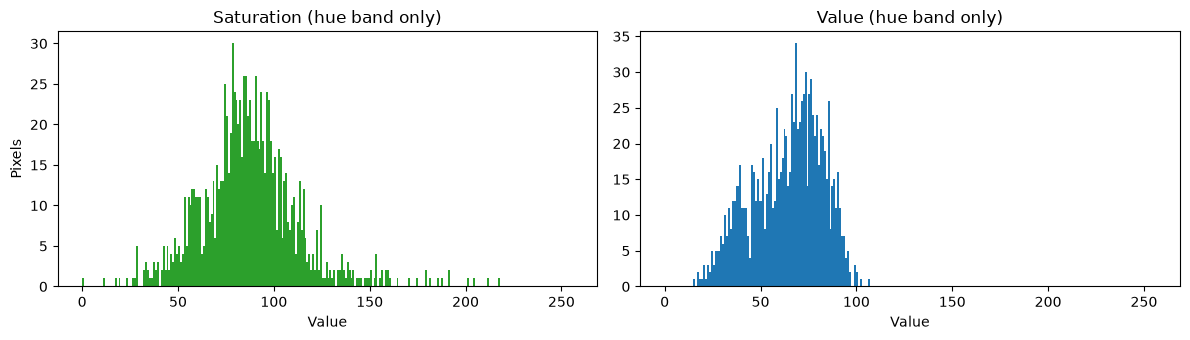

In [7]:
# Where do yellow/brown pixels live in S and V?
# Restrict to a hue band (OpenCV hue 5-25 = orange-brown/yellow) and inspect S and V there.
HUE_LO, HUE_HI = 0, 20
hue_band = (H >= HUE_LO) & (H <= HUE_HI)
print(f"Pixels inside hue band [{HUE_LO}, {HUE_HI}]: {hue_band.mean() * 100:.1f}% of the image")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(S[hue_band], bins=256, range=(0, 256), color="tab:green")
axes[0].set_title("Saturation (hue band only)")
axes[1].hist(V[hue_band], bins=256, range=(0, 256), color="tab:blue")
axes[1].set_title("Value (hue band only)")
for ax in axes:
    ax.set_xlabel("Value")
axes[0].set_ylabel("Pixels")
plt.tight_layout()
plt.show()

#### <b> 2.3 CIELAB exploration </b>

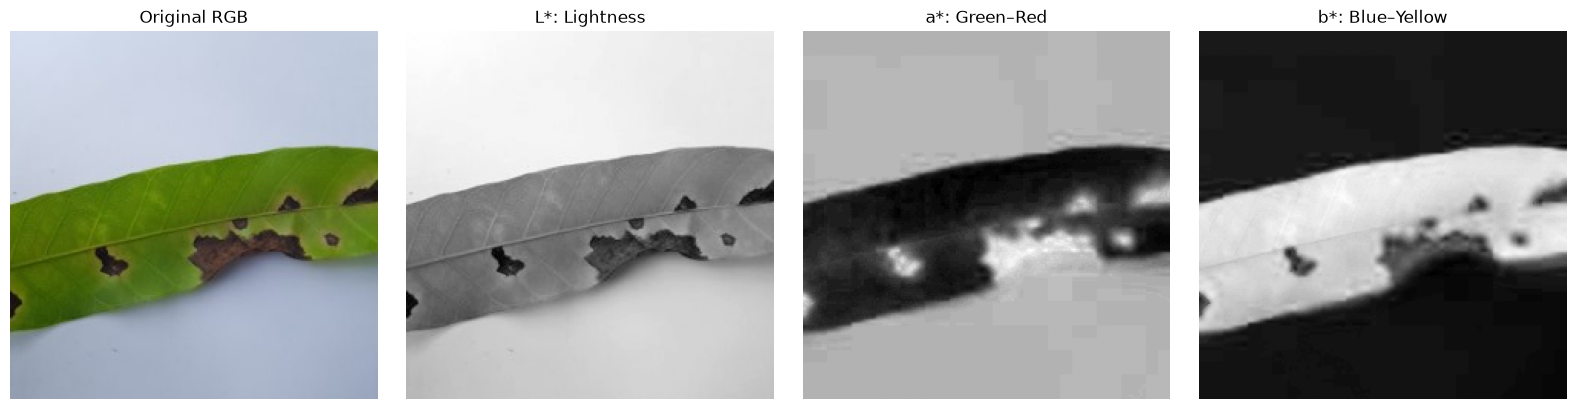

In [8]:
image_lab = cv2.cvtColor(rgb,cv2.COLOR_RGB2LAB)

L = image_lab[:, :, 0]
a = image_lab[:, :, 1]
b = image_lab[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(rgb)
axes[0].set_title("Original RGB")

axes[1].imshow(L, cmap="gray")
axes[1].set_title("L*: Lightness")

axes[2].imshow(a, cmap="gray")
axes[2].set_title("a*: Green–Red")

axes[3].imshow(b, cmap="gray")
axes[3].set_title("b*: Blue–Yellow")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

**How to read each channel (8-bit OpenCV storage, neutral = 128 for a and b)**

| Channel | Dark pixel | Bright pixel |
|---|---|---|
| **L\*** | Dark (necrotic tissue, shadow) | Light (background, bright leaf surface) |
| **a\*** | Green dominant (healthy leaf) | Red / brown dominant (lesion) |
| **b\*** | Blue or neutral (gray background) | Yellow dominant (leaf surface, yellowing tissue) |

Because chromaticity (a\*, b\*) is decoupled from lightness (L\*), a brown lesion can be separated by *how red it is* rather than only by *how dark it is*.

#### <b> HISTOGRAM OF CIEL LAB Component L* , a*, adn b*

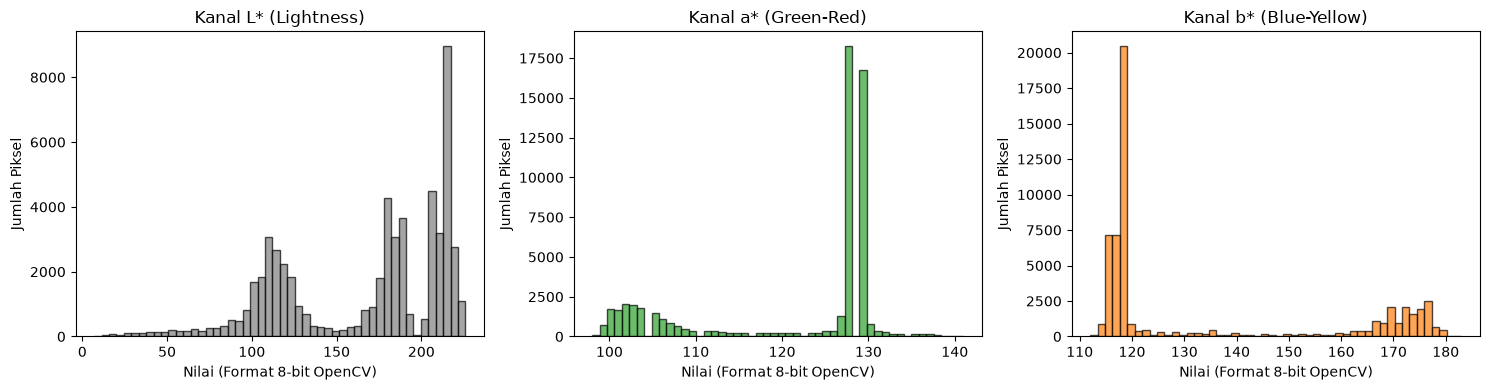

In [9]:
import matplotlib.pyplot as plt
import cv2

# Pastikan citra sudah dikonversi ke CIE Lab
# image_lab = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2LAB)

# Memecah kanal L*, a*, dan b*
L = image_lab[:, :, 0]
A = image_lab[:, :, 1]
B = image_lab[:, :, 2]

# Membuat 1 figure dengan 3 subplot (1 baris, 3 kolom)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

channels = [(L, "Kanal L* (Lightness)", "tab:gray"), 
            (A, "Kanal a* (Green-Red)", "tab:green"), 
            (B, "Kanal b* (Blue-Yellow)", "tab:orange")]

for ax, (ch, name, col) in zip(axes, channels):
    ax.hist(ch.ravel(), bins=50, color=col, alpha=0.7, edgecolor='black')
    ax.set_title(name)
    ax.set_xlabel("Nilai (Format 8-bit OpenCV)")
    ax.set_ylabel("Jumlah Piksel")

plt.tight_layout()
plt.show()


#### <p style='text-align:justify; background-color: #cbe4f2;  color: black ; padding: 20px;   border-radius: 12px;font-family: Arial, sans-serif; font-size: 16px; display: inline-block;'> To detect and distinguish lesion or disease areas, the use of the $a^*$ channel (green-red) has proven to be very effective because it provides clear separation, where the initial prediction of necrotic spots is generally concentrated within the $a$ channel value range of 130 to 140

### <b> 3. DATA PREPARATION

#### <b>3.1 Preprocessing: leaf mask (region of interest)

<div style='text-align:justify; background-color: #cbe4f2;  color: black ; padding: 20px;   border-radius: 12px;font-family: Arial, sans-serif; font-size: 16px; display: inline-block;'> 

In this stage, the leaf is isolated from the background to ensure that background pixels do not distort downstream statistics. We compare two segmentation strategies—Otsu Thresholding and GrabCut—to determine the most effective approach for leaf mask extraction:
- <b> Otsu Thresholding (RGB): </b>
    - Applies Otsu thresholding directly in the RGB color space.
    - Automatically identifies the "leaf" class based on higher mean intensity/saturation.
    - Uses morphological operations, retains the largest connected component, and fills holes so dark lesions do not punch holes in the mask.
- <b>GrabCut Segmentation: </b>
    - Uses iterative Graph-Cut energy minimization with Gaussian Mixture Models (GMMs) to refine foreground boundaries.
    - Initialized using the coarse mask from the RGB Otsu step (or a bounding box) as a seed.

NameError: name 'ret' is not defined

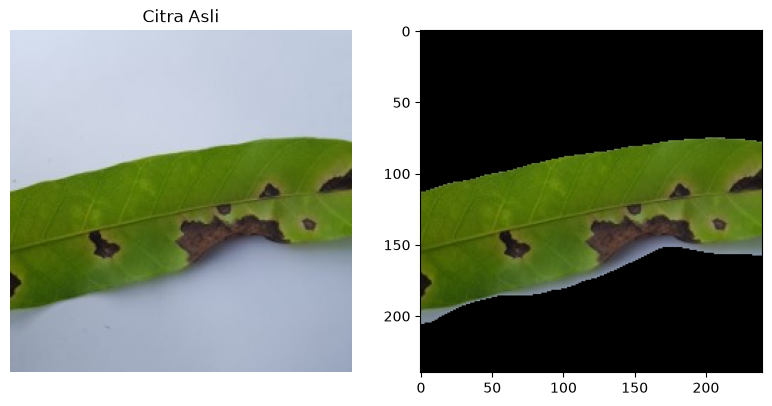

In [10]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

#Otsu
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
thresh_val, mask = cv2.threshold(
    blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)



#Grabcut
img = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
h, w = img.shape[:2]
x = int(w * 0.00)
y = int(h * 0.30)
rect_width = int(w * 1.00)
rect_height = int(h * 0.50)
rect = (x, y, rect_width, rect_height)

# Inisialisasi mask dan model GrabCut
gc_mask = np.zeros((h, w), np.uint8)
bgd_model = np.zeros((1, 65), np.float64)
fgd_model = np.zeros((1, 65), np.float64)

cv2.grabCut(
    img,
    gc_mask,
    rect,
    bgd_model,
    fgd_model,
    5,
    cv2.GC_INIT_WITH_RECT
)

# Gabungkan foreground pasti dan foreground mungkin
leaf_mask = np.where(
    (gc_mask == cv2.GC_FGD) |
    (gc_mask == cv2.GC_PR_FGD),
    255, 0
).astype(np.uint8)


# 5. Visualisasi Hasil Pemisahan Objek dan Background
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb)
plt.title("Citra Asli")
plt.axis('off')


leaf_only_otsu = cv2.bitwise_and(
    rgb, rgb, mask=mask
)

plt.subplot(1, 3, 2)
plt.imshow(leaf_only_otsu, cmap='gray')
plt.title(f"Mask Otsu (Threshold = {ret:.1f})")
plt.axis('off')

leaf_only_grabcut = cv2.bitwise_and(
    rgb, rgb, mask=leaf_mask
)

plt.subplot(1, 3, 3)
plt.imshow(leaf_only_grabcut, cmap='gray')
plt.title(f"Mask Grab Cut")
plt.axis('off')

plt.tight_layout()
plt.show()

<div style='text-align:justify; background-color: #cbe4f2;  color: black ; padding: 20px;   border-radius: 12px;font-family: Arial, sans-serif; font-size: 16px; display: inline-block;'> 
In this project, <b>the GrabCut mask was selected</b> over the Otsu mask because it produced a more precise segmentation of the leaf. Otsu’s method relies on a single global threshold applied to grayscale intensity, so it cannot distinguish regions by color or spatial context. As a result, dark anthracnose lesions and shadowed areas can be confused with the background, which leads to ragged boundaries and missing regions. GrabCut, in contrast, models the foreground and background color distributions with Gaussian Mixture Models and iteratively refines the labeling through graph cuts, which accounts for both color similarity and spatial coherence between neighboring pixels. This allowed it to follow the leaf contour more closely and to keep the lesions inside the leaf region, giving a cleaner foreground mask for the subsequent color-based analysis.

### <b> 4 MODELLING

### <b> 4.1 Lesion segmentation: HSV Threshold

<div style='text-align:justify; background-color: #cbe4f2;  color: black ; padding: 20px;   border-radius: 12px;font-family: Arial, sans-serif; font-size: 16px; display: inline-block;'>  In this stage, lesion segmentation is performed based on HSV color space components. The lower and upper threshold values are determined empirically through trial and error, guided by histogram analysis and the specific pathological characteristics of the leaf disease.

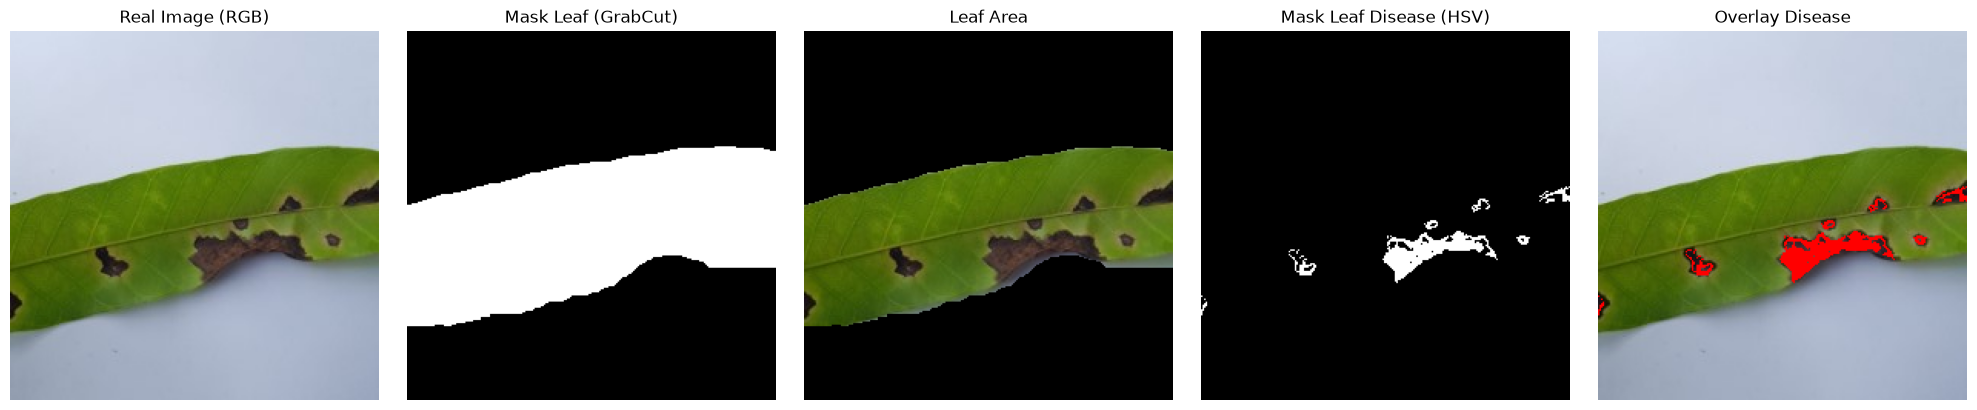

HSV lower: [ 0 50  0]
HSV upper: [ 25 150 100]
Disease pixels : 858pixels


In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


img = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)

# Bounding Box Grab Cut
h, w = img.shape[:2]
x = int(w * 0.00)
y = int(h * 0.30)
rect_width = int(w * 1.00)
rect_height = int(h * 0.50)
rect = (x, y, rect_width, rect_height)

# Inisialisasi mask dan model GrabCut
gc_mask = np.zeros((h, w), np.uint8)
bgd_model = np.zeros((1, 65), np.float64)
fgd_model = np.zeros((1, 65), np.float64)

cv2.grabCut(
    img,
    gc_mask,
    rect,
    bgd_model,
    fgd_model,
    5,
    cv2.GC_INIT_WITH_RECT
)

# Gabungkan foreground pasti dan foreground mungkin
leaf_mask = np.where(
    (gc_mask == cv2.GC_FGD) |
    (gc_mask == cv2.GC_PR_FGD),
    255, 0
).astype(np.uint8)



hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)

lower = np.array([0, 50, 0], dtype=np.uint8)
upper = np.array([25, 150, 100], dtype=np.uint8)

lesion_hsv_mask = cv2.inRange(hsv, lower, upper)


lesion_mask = cv2.bitwise_and(
    lesion_hsv_mask,
    leaf_mask
)

# Kurangi noise kecil
kernel = np.ones((3, 3), np.uint8)
lesion_mask = cv2.morphologyEx(
    lesion_mask, cv2.MORPH_OPEN, kernel
)


plt.figure(figsize=(20, 4))

plt.subplot(1, 5, 1)
plt.imshow(rgb)
plt.title("Real Image (RGB)")
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(leaf_mask, cmap="gray")
plt.title("Mask Leaf (GrabCut)")
plt.axis("off")

leaf_only = cv2.bitwise_and(
    rgb, rgb, mask=leaf_mask
)

plt.subplot(1, 5, 3)
plt.imshow(leaf_only)
plt.title("Leaf Area")
plt.axis("off")


plt.subplot(1, 5, 4)
plt.imshow(lesion_hsv_mask, cmap="gray")
plt.title("Mask Leaf Disease (HSV)")
plt.axis("off")


# Overlay lesi merah hanya di dalam daun
overlay_hsv = rgb.copy()
lesion_inside_leaf = (
    (lesion_hsv_mask > 0) &
    (leaf_mask > 0)
)
overlay_hsv[lesion_inside_leaf] = [255, 0, 0]

plt.subplot(1, 5, 5)
plt.imshow(overlay_hsv)
plt.title("Overlay Disease")
plt.axis("off")

#
plt.tight_layout()
plt.show()

print(f"HSV lower: {lower}")
print(f"HSV upper: {upper}")
print(f"Disease pixels : {np.count_nonzero(lesion_mask)}pixels")


<div style='text-align:justify; background-color: #cbe4f2;  color: black ; padding: 20px;   border-radius: 12px;font-family: Arial, sans-serif; font-size: 16px; display: inline-block;'>

Note that in this research, the Hue range is set from 0 to 179 (covering the full spectrum). This configuration was chosen because prior analysis of the Hue channel revealed that it does not provide reliable information to differentiate between the disease lesions and the background. Furthermore, relying on Hue introduced artifacts, appearing as white pixels over extremely dark or black lesion areas.

</div>

### <b> 4.2 Lesion segmentation: CIELAB Threshold

### <b> 4.1 Lesion segmentation: CIELAB Threshold </b>

<div style='text-align:justify; background-color: #cbe4f2;  color: black ; padding: 20px;   border-radius: 12px;font-family: Arial, sans-serif; font-size: 16px; display: inline-block;'>  In Similiar to HSV, this stage, lesion segmentation is performed based on Lightning*, a*, b* color space components. The lower and upper threshold values are determined empirically through trial and error, guided by histogram analysis and the specific pathological characteristics of the leaf disease

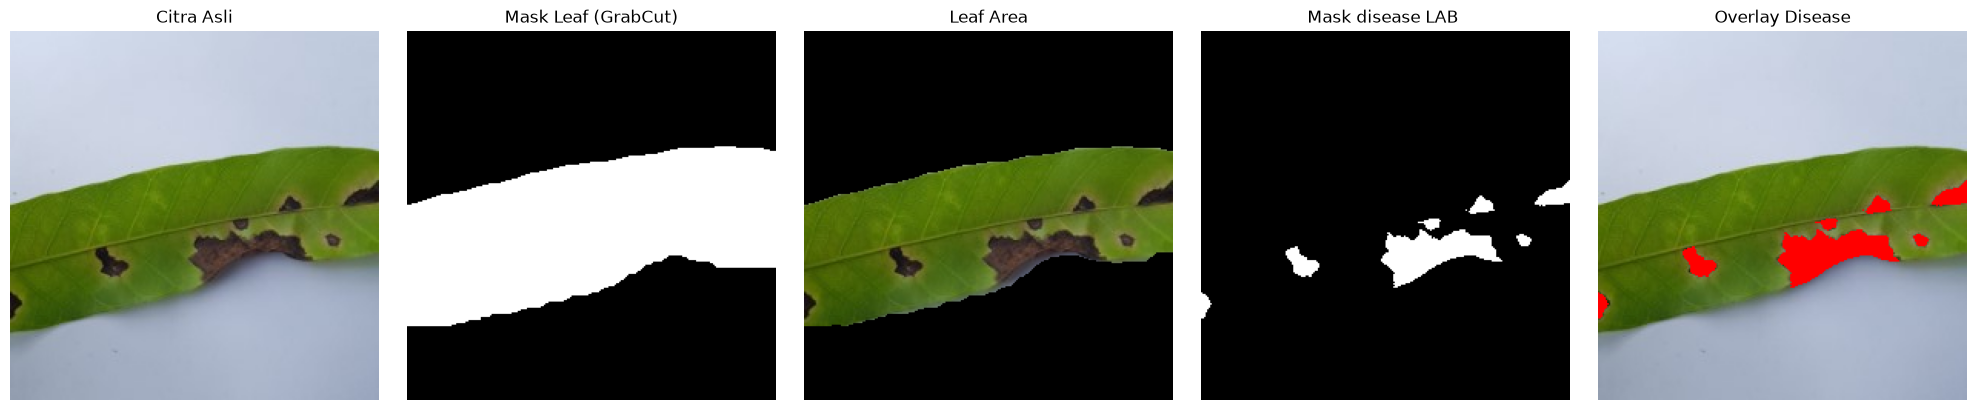

HSV lower: [ 0 50  0]
HSV upper: [ 25 150 100]
Luas piksel lesi: 858


In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


img = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)

# Bounding Box Grab Cut
h, w = img.shape[:2]
x = int(w * 0.00)
y = int(h * 0.30)
rect_width = int(w * 1.00)
rect_height = int(h * 0.50)
rect = (x, y, rect_width, rect_height)

# Inisialisasi mask dan model GrabCut
gc_mask = np.zeros((h, w), np.uint8)
bgd_model = np.zeros((1, 65), np.float64)
fgd_model = np.zeros((1, 65), np.float64)

cv2.grabCut(
    img,
    gc_mask,
    rect,
    bgd_model,
    fgd_model,
    5,
    cv2.GC_INIT_WITH_RECT
)

# Gabungkan foreground pasti dan foreground mungkin
leaf_mask = np.where(
    (gc_mask == cv2.GC_FGD) |
    (gc_mask == cv2.GC_PR_FGD),
    255, 0
).astype(np.uint8)



img_lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)

lower_lab = np.array([0, 120, 115], dtype=np.uint8)
upper_lab = np.array(
    [102, 145, 200], dtype=np.uint8
)  

disease_lab_mask = cv2.inRange(img_lab, lower_lab, upper_lab)

disease_mask_lab = cv2.bitwise_or(
    disease_lab_mask,
    leaf_mask
)

# Kurangi noise kecil
kernel = np.ones((3, 3), np.uint8)
disease_mask_lab = cv2.morphologyEx(
    disease_mask_lab, cv2.MORPH_OPEN, kernel
)


plt.figure(figsize=(20, 4))

plt.subplot(1, 5, 1)
plt.imshow(rgb)
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(leaf_mask, cmap="gray")
plt.title("Mask Leaf (GrabCut)")
plt.axis("off")

plt.subplot(1, 5, 3)
plt.imshow(leaf_only)
plt.title("Leaf Area")
plt.axis("off")

plt.subplot(1, 5, 4)
plt.imshow(disease_lab_mask, cmap="gray")
plt.title("Mask disease LAB ")
plt.axis("off")


# Overlay lesi merah hanya di dalam daun
overlay_lab = rgb.copy()
disease_inside_leaf = (
    (disease_lab_mask > 0) &
    (leaf_mask > 0)
)
overlay_lab[disease_inside_leaf] = [255, 0, 0]

plt.subplot(1, 5, 5)
plt.imshow(overlay_lab)
plt.title("Overlay Disease")
plt.axis("off")

# Background di luar daun dibuat hitam
leaf_only = cv2.bitwise_and(
    rgb, rgb, mask=leaf_mask
)



plt.tight_layout()
plt.show()

print(f"HSV lower: {lower}")
print(f"HSV upper: {upper}")
print(f"Luas piksel lesi: {np.count_nonzero(lesion_mask)}")

### <b> 5. VISUAL EVALUATION 

(-0.5, 239.5, 239.5, -0.5)

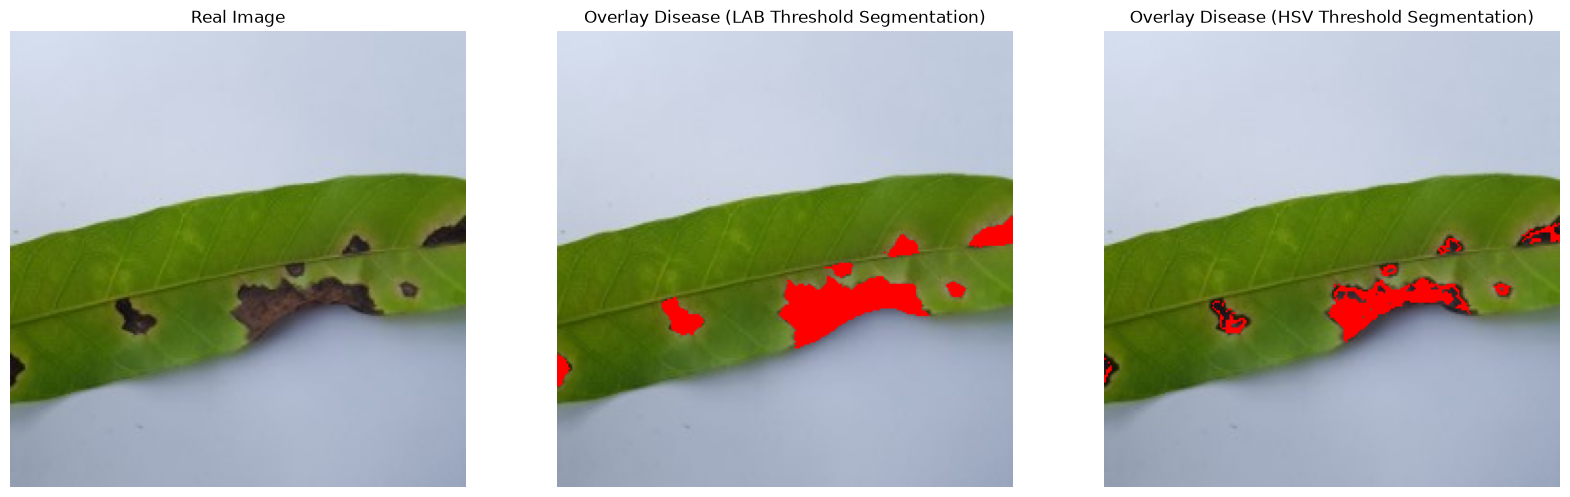

In [ ]:
plt.figure(figsize=(20, 8))

plt.subplot(1, 3, 1)
plt.imshow(rgb)
plt.title("Real Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(overlay_lab)
plt.title("Overlay Disease (LAB Threshold Segmentation)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay_hsv)
plt.title("Overlay Disease (HSV Threshold Segmentation)")
plt.axis("off")

<div style='text-align:justify; background-color: #cbe4f2;  color: black ; padding: 20px;   border-radius: 12px;font-family: Arial, sans-serif; font-size: 16px; display: inline-block;'> 

A visual analysis of the segmentation results demonstrates that LAB thresholding significantly outperforms HSV thresholding in capturing the complete structure of anthracnose lesions:

- <b> Mask Completeness & Coverage: </b>

    - LAB Thresholding: Generates a full, contiguous mask that completely covers the necrotic regions, including the large, primary lesion located in the center.

    - HSV Thresholding: Suffers from severe internal hollow gaps, marking primarily the lesion edges and missing the inner necrotic tissue.

- <b> Boundary Precision & Quality: </b>

    - LAB Thresholding: Produces smooth, coherent contours that closely match the true anatomical boundaries of the lesions seen in the original image.

    - HSV Thresholding: Yields fragmented, noisy, and irregular boundaries that fail to define the lesion margins clearly.

- <b> Artifact Resistance: </b>

    - LAB Thresholding: Effectively preserves dark/black central lesion cores without introducing false gaps or pixel artifacts.

    - HSV Thresholding: Struggles with extreme intensity variations, resulting in incomplete detection within deeply necrotic areas.

Conclusion:

Due to its superior spatial continuity, accurate boundary definition, and robust coverage of necrotic zones, the LAB color space was selected as the most suitable method for segmenting anthracnose lesions in this project.